# Spectral maps: Isotropic backgrounds, Static sky and the kinematic dipole

The sky is the sum of the Isotropic backgrounds (CMB blackbody, y with
relativistic corrections, μ, CIB, extragalactic CO), observed with the exact
Boost from the solar plus orbital velocity (ADR 0002), and of the Static sky
(pysm3 foregrounds and CMB anisotropies, with the orbital Doppler term,
ADR 0003). No zodiacal light or noise yet. The sky estimate assumes perfect
calibration. The first run builds the Static-sky cache (about 30 s).

In [1]:
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

from fossil_sim.config import load_config
from fossil_sim.input_sky import isotropic_background_mjy_sr, solar_velocity_km_s
from fossil_sim.orbit import L2Orbit
from fossil_sim.simulation import run_simulation
from fossil_sim.spectra import (
    blackbody_mjy_sr,
    cib_mjy_sr,
    extragalactic_co_mjy_sr,
    mu_distortion_mjy_sr,
    relativistic_sz_correction_mjy_sr,
    y_distortion_mjy_sr,
)

config = load_config(Path.cwd().parent / "configs" / "baseline.toml")
sky = config.sky

## Rest-frame spectra of the Isotropic backgrounds

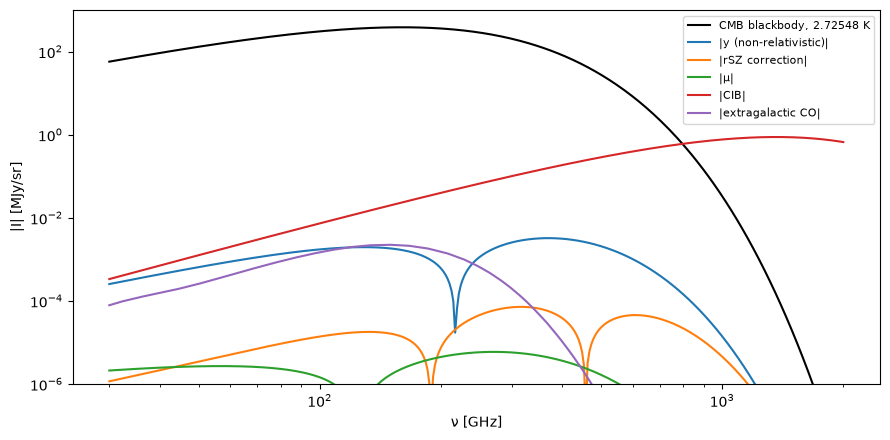

In [2]:
freq_ghz = np.geomspace(30, 2000, 400)
t_k = sky.t_cmb_k
components = {
    "y (non-relativistic)": y_distortion_mjy_sr(freq_ghz, sky.y, t_k),
    "rSZ correction": relativistic_sz_correction_mjy_sr(
        freq_ghz, sky.y, sky.y_electron_temperature_kev, t_k
    ),
    "μ": mu_distortion_mjy_sr(freq_ghz, sky.mu, t_k),
    "CIB": cib_mjy_sr(
        freq_ghz,
        sky.cib_amplitude,
        sky.cib_spectral_index,
        sky.cib_temperature_k,
        sky.cib_reference_freq_ghz,
    ),
    "extragalactic CO": extragalactic_co_mjy_sr(freq_ghz, sky.co_amplitude),
}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(freq_ghz, blackbody_mjy_sr(freq_ghz, t_k), "k", label=f"CMB blackbody, {t_k} K")
for name, values in components.items():
    ax.plot(freq_ghz, np.abs(values), label=f"|{name}|")
ax.set(
    xscale="log",
    yscale="log",
    ylim=(1e-6, 1e3),
    xlabel="ν [GHz]",
    ylabel="|I| [MJy/sr]",
)
ax.legend(fontsize=8)
fig.tight_layout()

## Dipole amplitude along the year

The observed dipole follows |v_sun + v_orbit(t)|: the orbital term modulates it
by about ±30 km/s over the year.

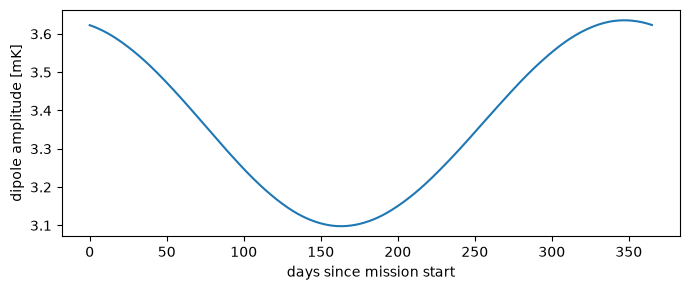

In [3]:
orbit = L2Orbit(config.orbit, config.simulation.mission_start_time, 365.25 * 86400)
days = np.linspace(0, 365, 500)
v_km_s = solar_velocity_km_s(sky) + orbit.position_velocity(days * 86400)[1]
dipole_mk = 1e3 * t_k * np.linalg.norm(v_km_s, axis=1) / 299792.458
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(days, dipole_mk)
ax.set(xlabel="days since mission start", ylabel="dipole amplitude [mK]")
fig.tight_layout()

## Static sky

The cached alm cube sampled on a HEALPix grid (ecliptic coordinates), and its
orbital Doppler term: on the Galactic plane at THz frequencies it is far
larger than the y distortion.

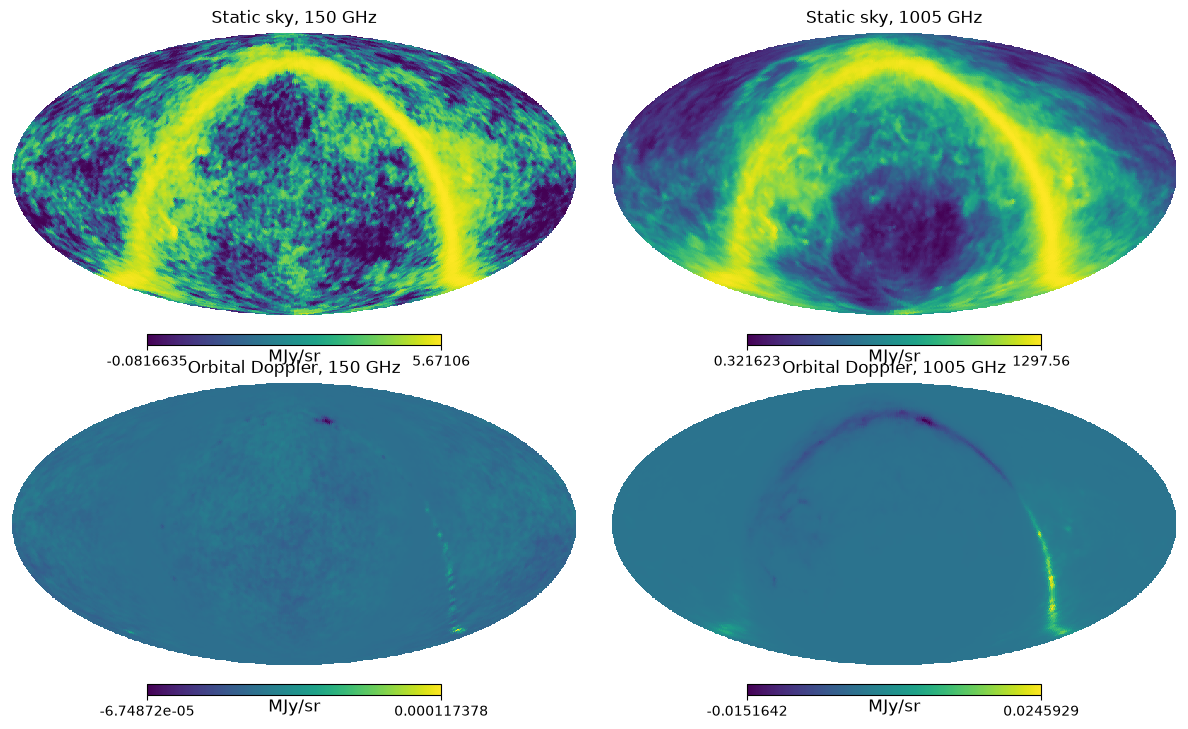

In [4]:
from fossil_sim.input_sky import StaticSky, orbital_doppler_mjy_sr
from fossil_sim.instrument import frequency_grid_ghz

grid_ghz = frequency_grid_ghz(config.instrument)
static = StaticSky(config.static_sky, grid_ghz, config.instrument.beam_fwhm_deg)
nside = 64
vectors = np.array(hp.pix2vec(nside, np.arange(hp.nside2npix(nside)))).T
static_maps = static.sample(vectors)
v_orbit = np.broadcast_to(orbit.position_velocity(0.0)[1][0], vectors.shape)
doppler = orbital_doppler_mjy_sr(grid_ghz, static_maps, vectors, v_orbit)
fig = plt.figure(figsize=(12, 7))
for k, freq in enumerate((150, 1005)):
    i = np.argmin(np.abs(grid_ghz - freq))
    hp.mollview(
        static_maps[:, i],
        fig=fig,
        sub=(2, 2, k + 1),
        norm="hist",
        title=f"Static sky, {freq} GHz",
        unit="MJy/sr",
    )
    hp.mollview(
        doppler[:, i],
        fig=fig,
        sub=(2, 2, k + 3),
        title=f"Orbital Doppler, {freq} GHz",
        unit="MJy/sr",
    )

## 30 days of spectral maps

Fitted dipole (|b| > 30°): 3.5581 mK


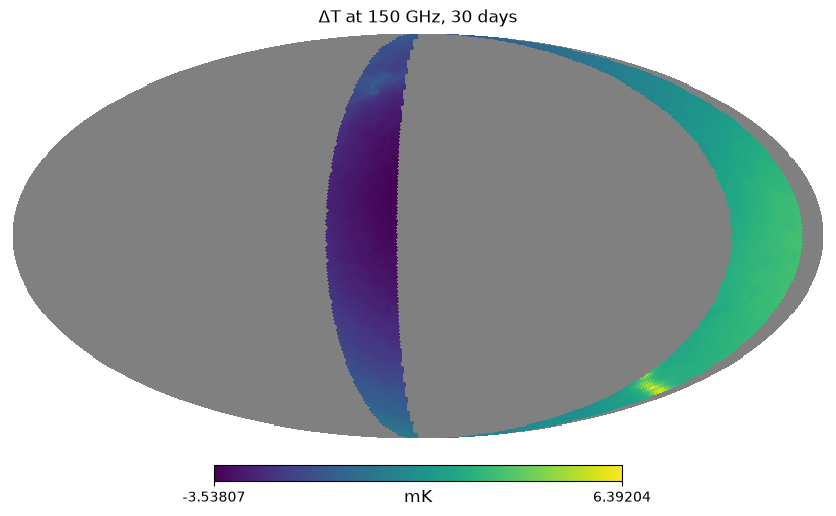

In [5]:
result = run_simulation(config, num_of_cycles=21)
maps = result.spectral_maps
sky_map = maps.sky_map(64)
seen = sky_map[0] != hp.UNSEEN
i150 = np.argmin(np.abs(maps.freq_ghz - 150))
f = maps.freq_ghz[i150]
dbdt = (blackbody_mjy_sr(f, t_k + 1e-4) - blackbody_mjy_sr(f, t_k - 1e-4)) / 2e-4
delta_t_mk = np.full(sky_map.shape[1], hp.UNSEEN)
delta_t_mk[seen] = (
    1e3 * (sky_map[i150, seen] - isotropic_background_mjy_sr(f, sky)) / dbdt
)
hp.mollview(delta_t_mk, title=f"ΔT at {f:.0f} GHz, 30 days", unit="mK")
# Fit the dipole away from the Galactic plane (|b| > 30°)
gal_vectors = hp.Rotator(coord=["E", "G"])(
    np.array(hp.pix2vec(64, np.arange(hp.nside2npix(64))))
)
high_latitude = np.abs(gal_vectors[2]) > np.sin(np.deg2rad(30))
_, dipole = hp.fit_dipole(np.where(seen & high_latitude, delta_t_mk, hp.UNSEEN))
print(f"Fitted dipole (|b| > 30°): {np.linalg.norm(dipole):.4f} mK")

## Diagnostic maps

The same output (L) in B10 and B01 sees the sky with opposite sign; the
difference doubles the sky and cancels any common instrumental offset.

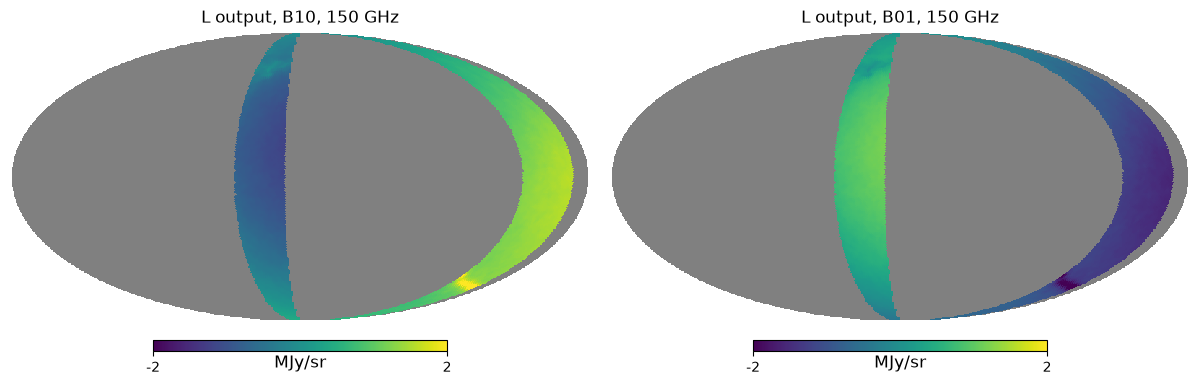

In [6]:
raw = maps.raw_maps(64)
fig = plt.figure(figsize=(12, 3.5))
for k, mode in enumerate(("B10", "B01")):
    hp.mollview(
        raw[0, k, i150],
        fig=fig,
        sub=(1, 2, k + 1),
        title=f"L output, {mode}, {f:.0f} GHz",
        unit="MJy/sr",
        min=-2,
        max=2,
    )